# Renk Maskesi Kutu Değerlendirmesi ve TP / FP / FN — Murathan

**Hazır dedektör kullanılmamıştır** (yönerge 6. madde isteğe bağlıdır). Renk maskesinin bağlı bileşenleri aday kutu olur ve elle çizilmiş gerçek baret kutularıyla **IoU ≥ 0.50** bire bir eşleştirilir: eşleşme **TP**, eşleşmeyen aday **FP**, bulunamayan baret **FN**. Kutu = "sarı renkli bölge"; kutunun bulunması baretin başta olduğunu göstermez. Confidence değeri yoktur.

In [1]:
from pathlib import Path
import sys
KOK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kaynak" / "analiz.py").is_file())
sys.path.insert(0, str(KOK))

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from kaynak.veri import ayarlari_oku, veri_setini_oku, goruntu_oku, maske_oku
from kaynak.analiz import analiz_et
from kaynak.gorsel import bgr2rgb, kutulari_ciz, maske_bindir
ayarlar = ayarlari_oku()
kayitlar = veri_setini_oku()
pd.set_option("display.max_colwidth", 80)
print("Görüntüler:", ", ".join(f"{k['kimlik']} ({k['bolum']})" for k in kayitlar))

Görüntüler: G1 (gelistirme), G2 (gelistirme), K1 (kontrol), K2 (kontrol), K3 (kontrol), K4 (kontrol)


## 1. Dondurulmuş ayarlar

In [2]:
print(ayarlar["kutu_degerlendirme"])

{'dondurulmus': True, 'morfoloji_cekirdegi': 3, 'en_kucuk_bilesen_piksel': 50, 'iou_esigi': 0.5, 'not': 'Renk maskesinin bağlı bileşenleri aday kutu olur; elle çizilmiş baret kutularıyla IoU >= 0.50 bire bir eşleşme TP, eşleşmeyen aday FP, bulunamayan baret FN. Hazır dedektör kullanılmadı.'}


## 2. Deney öncesi tahmin

In [3]:
tahminler = pd.read_csv(KOK / "belgeler/tahminler.csv")
benim = tahminler[(tahminler.uye == "Murathan")]
if benim.empty:
    print("UYARI: Bu deney için kayıtlı tahmin yok. Hoca: 'Tahmini olmayan deney puanlanmaz.'")
    print("Deneyi çalıştırmadan ÖNCE belgeler/tahminler.csv dosyasına iki cümle ekleyin.")
for _, t in benim.iterrows():
    print(f"[{t.kayit_tarihi}] {t.deney_kimligi}\n 1) {t.tahmin_1}\n 2) {t.tahmin_2}\n   ({t.durum})\n")

[2026-11-02] color_mask_box_eval
 1) Renk maskesinden çıkan kutuların baret dışı sarı nesneler (yelek, ekipman) yüzünden özellikle RGB'de çok sayıda FP üreteceğini, K4'te elde tutulan bareti ise TP olarak bulacağını ama bunun baretin başta olduğunu göstermeyeceğini bekliyorum.
 2) K2'deki karanlık baretin renk aralığının dışında kalıp FN olacağını, K3'teki uzak ve küçük baretlerin de maskede parçalı ve küçük kalacağı için IoU>=0.50'yi sağlayamayıp FN olacağını bekliyorum.
   (üye tarafından yazıldı)



## 3. IoU ve eşleştirme kuralının elle kontrolü

In [4]:
from kaynak.olcum import iou, kutulari_degerlendir
gt = [981, 94, 1070, 165]
print("IoU(kendisi) =", iou(gt, gt))
d = kutulari_degerlendir([gt, [985, 97, 1072, 168], [10, 10, 60, 60]], [gt])
print("Aynı barete iki kutu + bir alakasız kutu -> TP/FP/FN =", d["tp"], d["fp"], d["fn"])

IoU(kendisi) = 1.0
Aynı barete iki kutu + bir alakasız kutu -> TP/FP/FN = 1 2 0


## 4. Geliştirme ve kontrol sonuçları

In [5]:
t = pd.read_csv(KOK / "sonuclar/temel_sonuclar.csv")
t[["kimlik", "bolum", "yontem", "aday_kutu", "tp", "fp", "fn", "eslesen_iou", "piksel_kesinlik_yuzde", "piksel_duyarlilik_yuzde"]]

,kimlik,bolum,yontem,aday_kutu,tp,fp,fn,eslesen_iou,piksel_kesinlik_yuzde,piksel_duyarlilik_yuzde
0,G1,gelistirme,RGB,24,1,23,0,0.85,NaN,NaN
1,G1,gelistirme,HSV,10,1,9,0,0.85,NaN,NaN
2,G2,gelistirme,RGB,0,0,0,0,-,NaN,NaN
3,G2,gelistirme,HSV,0,0,0,0,-,NaN,NaN
4,K1,kontrol,RGB,2,0,2,1,-,NaN,NaN
5,K1,kontrol,HSV,1,1,0,0,0.81,NaN,NaN
6,K2,kontrol,RGB,3,0,3,2,-,NaN,NaN
7,K2,kontrol,HSV,3,1,2,1,0.65,NaN,NaN
8,K3,kontrol,RGB,27,0,27,0,-,NaN,NaN
9,K3,kontrol,HSV,33,0,33,0,-,NaN,NaN


In [6]:
k = t[t.bolum == "kontrol"].groupby("yontem")[["tp", "fp", "fn"]].sum()
k["gercek_baret"] = sum(len(r["baret_kutulari"]) for r in veri_setini_oku("kontrol")); k

,tp,fp,fn,gercek_baret
yontem,,,,
HSV,3,36,1,4
RGB,1,45,3,4


## 5. Görseller
Yeşil: gerçek baret · Mavi: TP · Kırmızı: FP · Gri: baş ROI

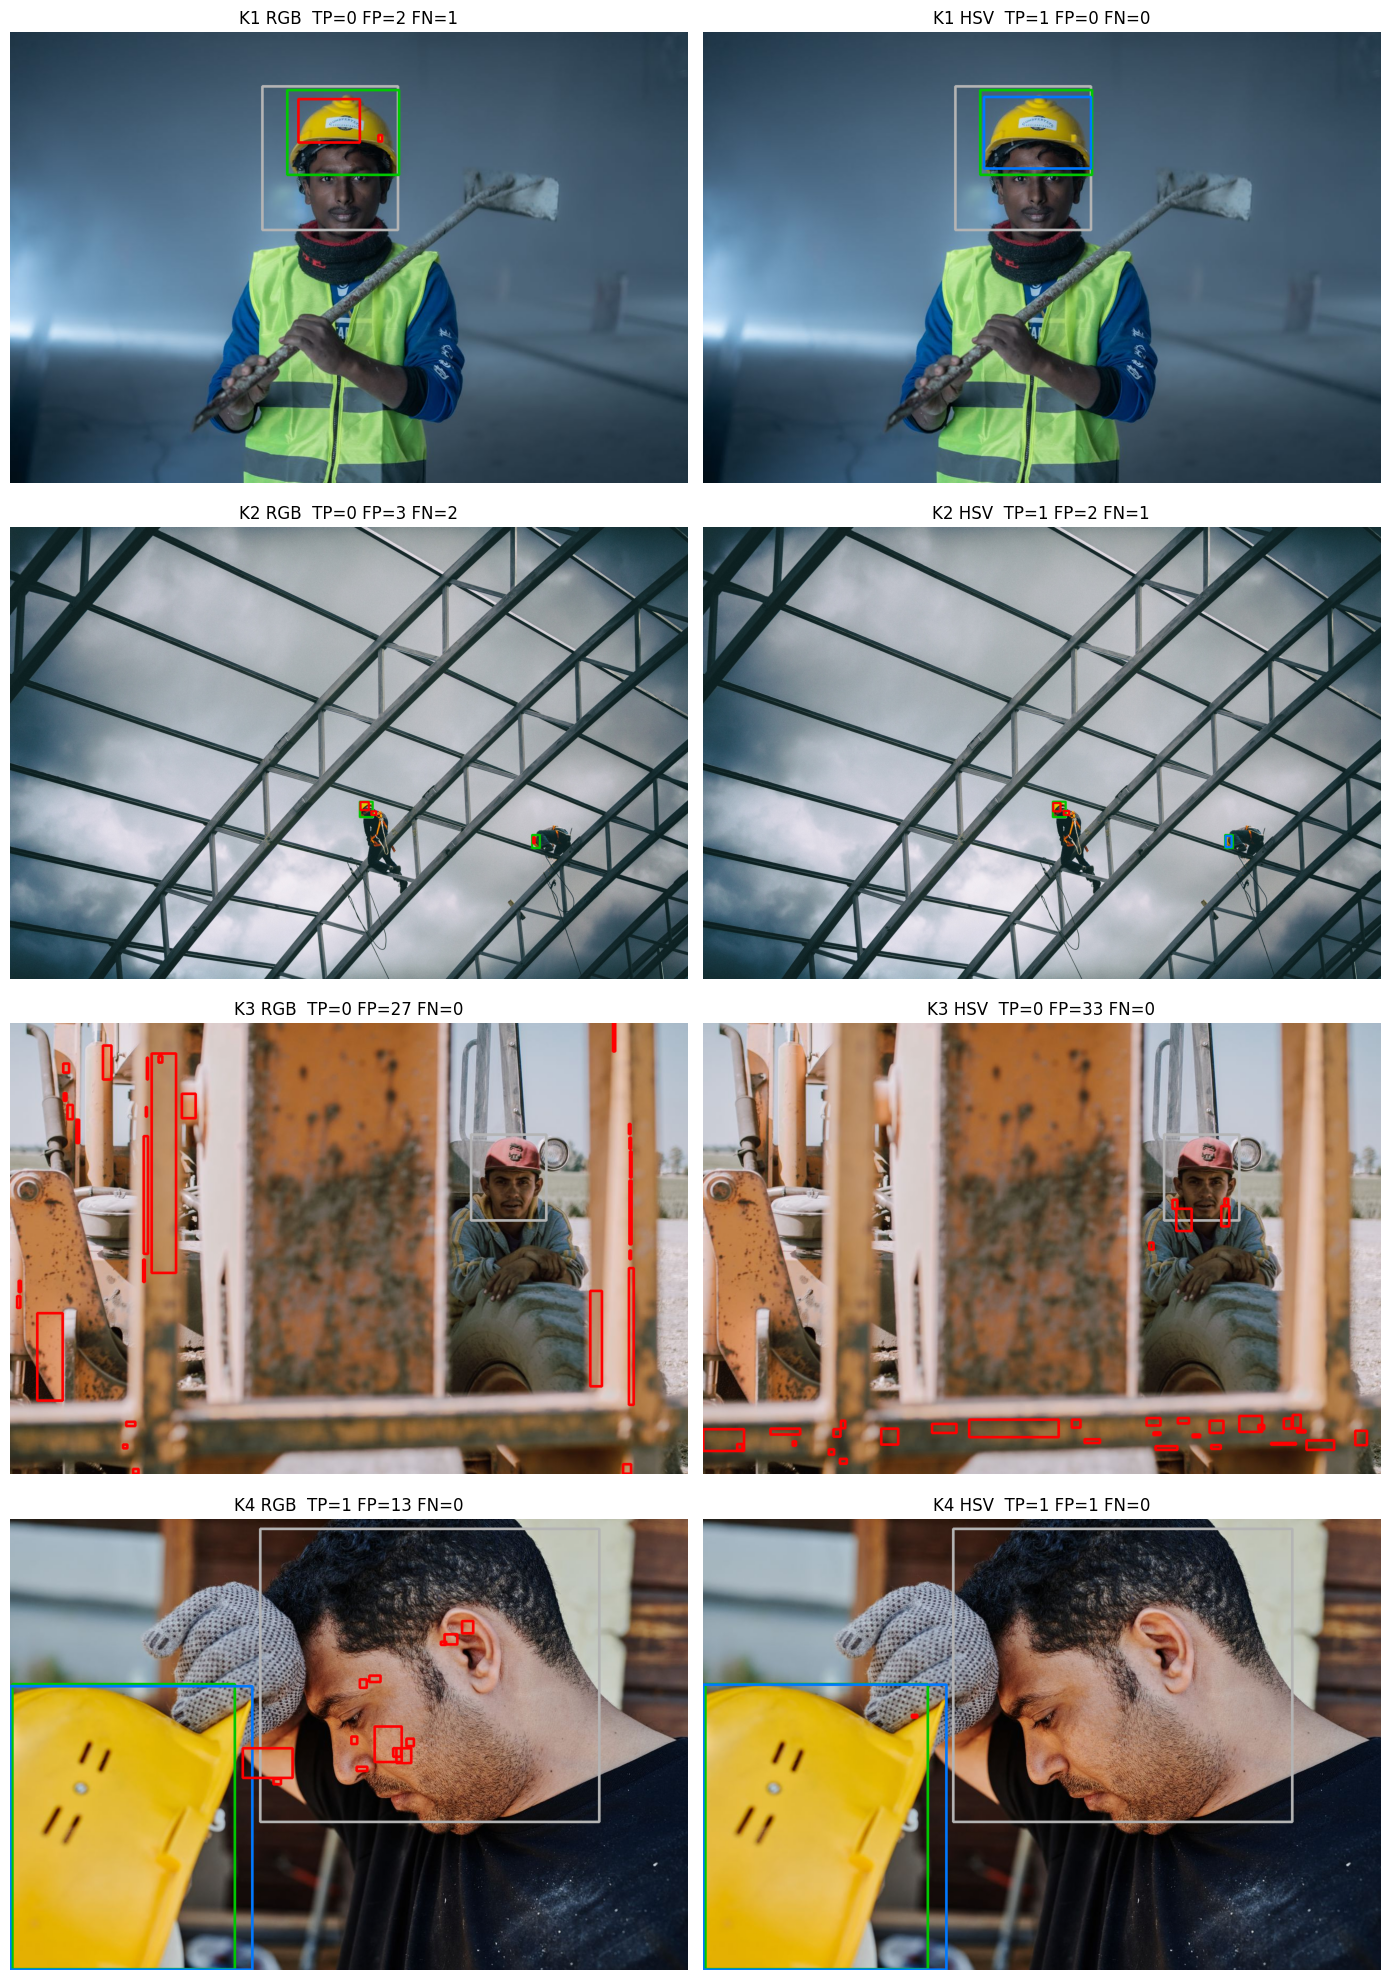

In [7]:
fig, eksen = plt.subplots(4, 2, figsize=(14, 20))
for satir, kimlik in zip(eksen, ("K1", "K2", "K3", "K4")):
    for e, uzay in zip(satir, ("rgb", "hsv")):
        e.imshow(bgr2rgb(goruntu_oku(KOK / f"sonuclar/kutular/{kimlik}_{uzay}.png")))
        r = t[(t.kimlik == kimlik) & (t.yontem == uzay.upper())].iloc[0]
        e.set_title(f"{kimlik} {uzay.upper()}  TP={r.tp} FP={r.fp} FN={r.fn}"); e.axis("off")
plt.tight_layout(); plt.show()

## 6. Yanlış alarm ve kaçırma — neden ve sonraki kontrol

**Sayım notu:** TP/FP/FN nesne (kutu) düzeyidir; görüntünün dört sınıflı doğru/yanlış sayısı ayrı tutulur (`sonuclar/sonuc_tablosu.md`). Confidence değeri yoktur.

**Yanlış alarm — K3 (baret yok, sarı-turuncu iş makinesi).** RGB maskesi makinede %2.65 alan seçti (27 FP) ve kural, görüntüde baret yokken *baret var, başta değil* dedi; HSV de 33 FP üretti ama alanı %1.46'da kaldığı için sınıf doğru çıktı. *Neden:* yöntem şekle değil yalnızca renge bakıyor; renkli bölgeyi bulmak baret nesnesini tanımak değildir (H1, S2). *Sonraki kontrol:* aday kutulara en–boy oranı ve doluluk ölçütünü geliştirme setinde tanımlayıp K3'te yeniden ölçmek.

**Kaçırma — K1 (loş ışık) ve K2 (uzak, küçük).** HSV K1'deki bareti IoU 0.81 ile buldu ve baş örtüşmesi %12.69 oldu; K2'de baş örtüşmesi %17.88. Buna rağmen görüntünün tamamındaki renkli alan %0.81 ve %0.03 olduğu için kural *baret yok* dedi. RGB ise K1'de baretin yalnızca bir kısmını seçti (IoU 0.28 → FN). *Neden:* kuraldaki %2.5 alan eşiği görüntünün tamamına göre hesaplanıyor ve küçük ya da uzak bareti cezalandırıyor; loş ışıkta RGB alt sınırı (R ≥ 180) baret piksellerini dışarıda bırakıyor. *Sonraki kontrol:* alan eşiğini baş ROI çevresinde hesaplayan kuralı G1/G2'de tanımlayıp aynı K1–K4'te yeniden ölçmek.

**Kutu ≠ başta (S3) — K4.** Elde tutulan baret iki yöntemde de IoU 0.91 ile bulundu; doğru sınıf *baret var, başta değil*. Kutunun bulunması baretin başta olduğunu göstermez; karar baş ROI örtüşmesiyle ayrı verilir.

**Sınırlılık:** Altı görüntülük eğitim prototipidir; bu sayılar gerçek işyeri güvenilirliği iddiası taşımaz.